In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from credit_risk import config as C, data as D, features as F, scorecard as S, models as M
from credit_risk import calibration as CAL, business as B, fairness as FAIR, stability as ST
R = lambda s: json.load(open(C.REPORTS / f"metrics_{s}.json"))
def app():
    t = pd.read_parquet(C.ROOT / "data/synthetic/application_train.parquet")  # use data/raw + D.read_table for real data
    return F.engineer_application(D.clean_application(t)), t


# 05 - SHAP and reason codes

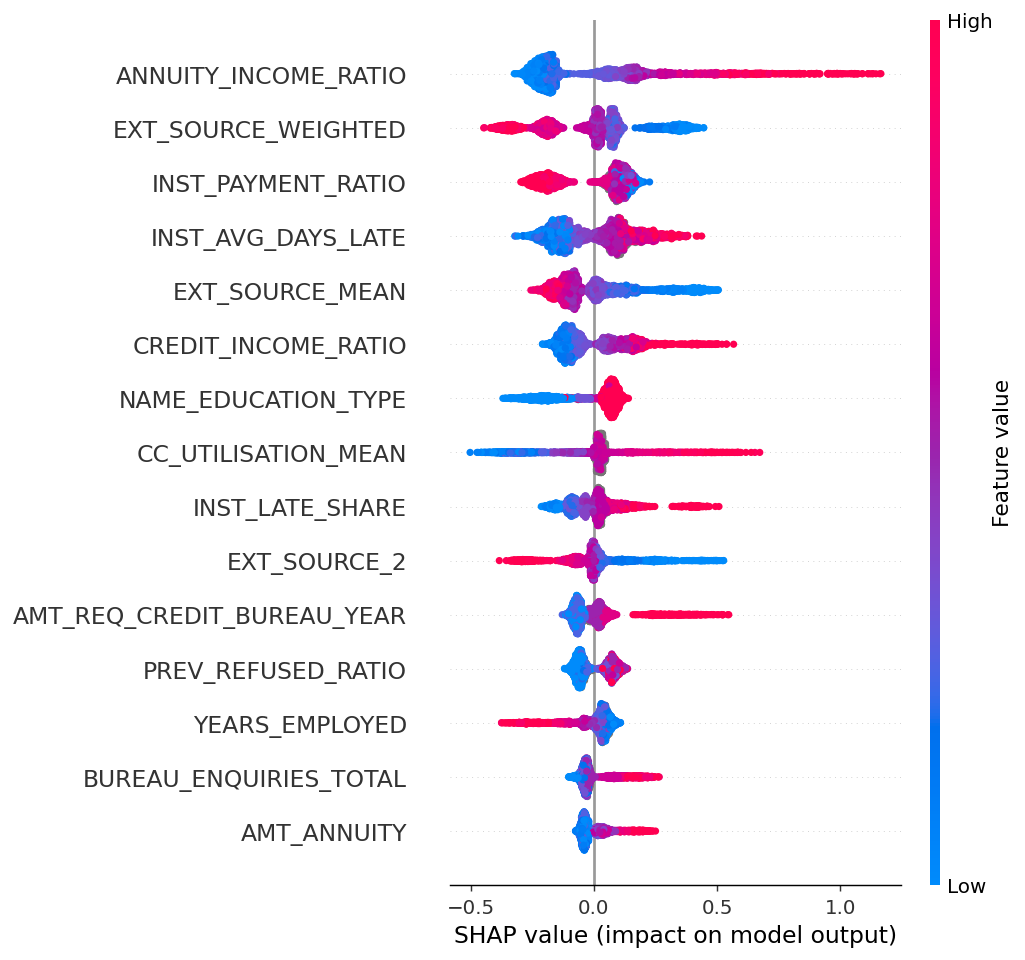

In [2]:
m = R('A'); display(Image(str(C.FIGURES / 'shap_summary.png')))

In [3]:
pd.DataFrame(m['explain']['top10'])

,feature,mean_abs_shap
0,ANNUITY_INCOME_RATIO,0.245330
1,EXT_SOURCE_MEAN,0.192337
2,EXT_SOURCE_WEIGHTED,0.161205
3,NAME_EDUCATION_TYPE,0.137807
4,BUREAU_ENQUIRIES_TOTAL,0.121881
5,CREDIT_INCOME_RATIO,0.117579
6,AMT_REQ_CREDIT_BUREAU_YEAR,0.114061
7,EXT_SOURCE_2,0.113599
8,YEARS_EMPLOYED,0.100645
9,DAYS_EMPLOYED,0.067143


In [4]:
for ex in m['explain']['examples']:
    print(ex['label'], f"PD={ex['pd']:.1%} score={ex['score']:.0f}")
    for r in ex['reason_codes']: print('   -', r['reason'], r['impact_log_odds'])

low risk PD=2.5% score=593
   - Education level 0.072
   - Many credit enquiries in the last year 0.072
   - Risk factor: Apartments Avg 0.068
   - Loan amount exceeds the price of the goods financed 0.061
medium risk PD=7.8% score=558
   - Loan amount is high relative to income 0.12
   - High instalment relative to income 0.102
   - Low overall external credit score 0.085
   - Risk factor: Flag Own Car 0.082
high risk PD=26.5% score=517
   - High instalment relative to income 0.654
   - Low external credit score (source 2) 0.29
   - Loan amount is high relative to income 0.174
   - Low overall external credit score 0.173


Spearman rank agreement of mean |SHAP| vs scorecard IV is in the metrics JSON (`explain.spearman_shap_vs_iv`).